# Test Notebook for Sonar PreProcessing and Filtering

In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import os 

In [2]:
imgs_path = '/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/'
image_files = sorted([
    f for f in os.listdir(imgs_path)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])

In [3]:
img = cv2.imread(os.path.join(imgs_path, image_files[-1]), cv2.IMREAD_GRAYSCALE)
assert img is not None, "file could not be read, check with os.path.exists()"

In [4]:
# Otsu's thresholding
ret2,th2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
 
# Otsu's thresholding after Gaussian filtering
blur = cv2.GaussianBlur(img,(15,15),0)
ret3,th3 = cv2.threshold(blur,150,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

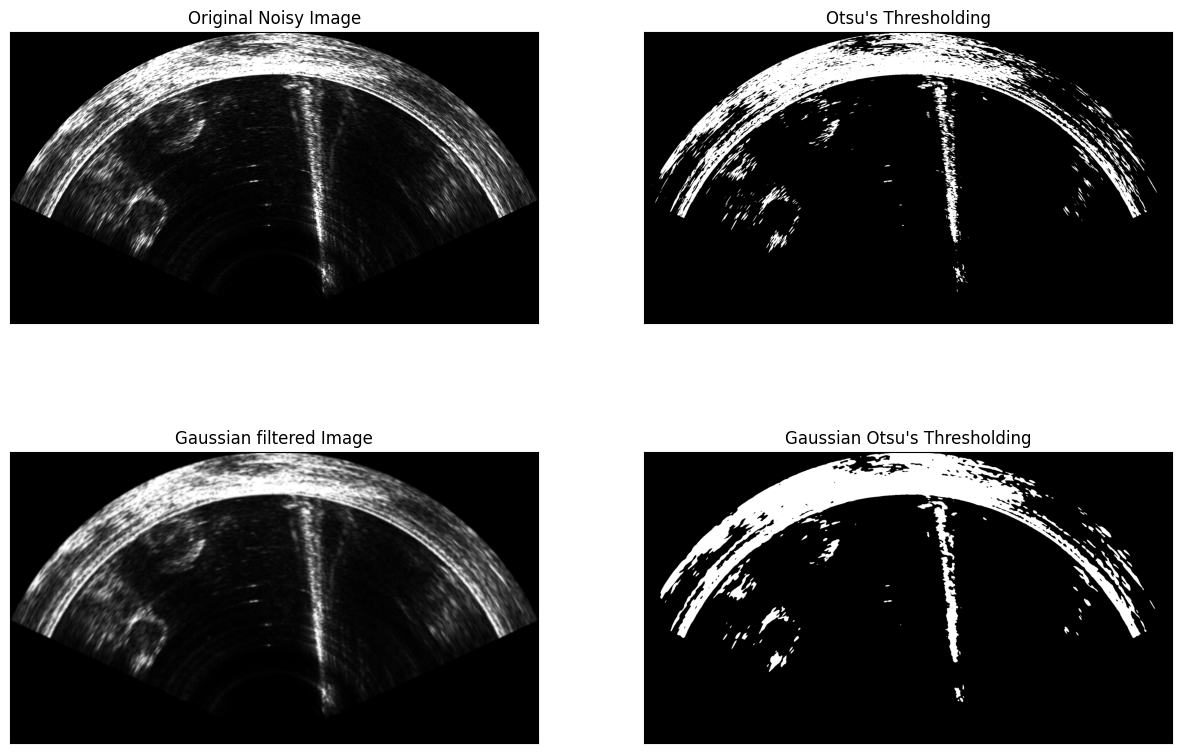

In [5]:
images = [img, th2,
          blur, th3]
titles = ['Original Noisy Image',"Otsu's Thresholding",
          'Gaussian filtered Image',"Gaussian Otsu's Thresholding"]
 
plt.figure(figsize=(15,10))
for i in range(2):
    # Image
    plt.subplot(2,2,i*2+1)
    plt.imshow(images[i*2],'gray')
    plt.title(titles[i*2])
    plt.xticks([])
    plt.yticks([])

    # # Hystogram
    # plt.subplot(2,3,i*3+2)
    # plt.hist(images[i*3].ravel(),256)
    # plt.title(titles[i*3+1])

    # Threshold
    plt.subplot(2,2,i*2+2)
    plt.imshow(images[i*2+1],'gray')
    plt.title(titles[i*2+1])
    plt.xticks([])
    plt.yticks([])

plt.show()

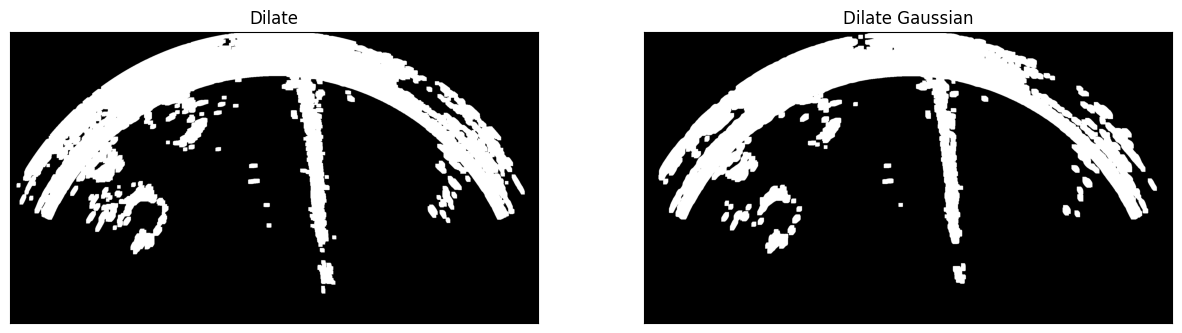

In [6]:
kernel = np.ones((15, 15), np.uint8)
img_dilation = cv2.dilate(th2, kernel, iterations=1)
img_gauss_dilation = cv2.dilate(th3, kernel, iterations=1)

plt.figure(figsize=(15,10))
# Image
plt.subplot(1,2,1)
plt.imshow(img_dilation,'gray')
plt.title('Dilate')
plt.xticks([])
plt.yticks([])

# Threshold
plt.subplot(1,2,2)
plt.imshow(img_gauss_dilation,'gray')
plt.title('Dilate Gaussian')
plt.xticks([])
plt.yticks([]) 

plt.show()

In [8]:
print(img_gauss_dilation == 1)

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
